In [ ]:
#Rotulagem de componentes conectados (Connected Component Labeling)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.measure import label
from scipy.spatial import cKDTree
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb, gray2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from skimage.util import invert
from skan import Skeleton, summarize
from itertools import combinations

def podar_esqueleto_por_orientacao(esqueleto_img, angulo_limite_graus=45):
    """
    Args:
        esqueleto_img (np.ndarray): A imagem binária do esqueleto.
        angulo_limite_graus (int): O desvio máximo em graus em relação à linha
                                   perfeita (180°) para considerar dois ramos
                                   como uma continuação.

    Returns:
        np.ndarray: A imagem do esqueleto podado.
    """
    # 1. Analisar o esqueleto
    skeleton_obj = Skeleton(esqueleto_img)
    summary = summarize(skeleton_obj)

    # Se não houver ramos, retorna a imagem original
    if summary.shape[0] == 0:
        print("Nenhum ramo encontrado no esqueleto.")
        return esqueleto_img

    esqueleto_podado = np.copy(esqueleto_img)

    # 2. Encontrar pontos de junção (NOVA LÓGICA)
    # Concatena todas as IDs de nós (origem e destino) em uma única lista
    todos_os_nos = pd.concat([summary['node-id-src'], summary['node-id-dst']], ignore_index=True)
    
    # Conta a ocorrência de cada ID de nó
    contagem_nos = todos_os_nos.value_counts()
    
    # Junções são os nós que aparecem mais de 2 vezes
    pontos_de_juncao = contagem_nos[contagem_nos > 2].index.tolist()

    print(f"Encontrados {len(pontos_de_juncao)} pontos de junção para análise.")

    # 3. Analisar cada junção
    for junction_id in pontos_de_juncao:
        j_coords = skeleton_obj.coordinates[junction_id]
        
        # Encontra todos os ramos conectados a essa junção
        ramos_conectados = summary[(summary['node-id-src'] == junction_id) | (summary['node-id-dst'] == junction_id)]
        
        if len(ramos_conectados) < 3:
            continue

        ramos_info = []
        for _, ramo in ramos_conectados.iterrows():
            # Pega o ID do ponto final do ramo (o que não é a junção)
            other_node_id = ramo['node-id-dst'] if ramo['node-id-src'] == junction_id else ramo['node-id-src']
            other_coords = skeleton_obj.coordinates[int(other_node_id)]

            # Calcula o vetor e o ângulo do ramo
            dy = other_coords[0] - j_coords[0]
            dx = other_coords[1] - j_coords[1]
            angle = np.degrees(np.arctan2(-dy, dx))
            
            ramos_info.append({'id': ramo['skeleton-id'], 'angle': angle})

        # 4. Aplicar a lógica de poda (esta parte não muda)
        melhor_par = None
        menor_diff_de_180 = 180

        for r1, r2 in combinations(ramos_info, 2):
            diff = abs(r1['angle'] - r2['angle'])
            diff_de_180 = abs(diff - 180)
            if diff_de_180 > 180:
                diff_de_180 = 360 - diff_de_180

            if diff_de_180 < menor_diff_de_180:
                menor_diff_de_180 = diff_de_180
                melhor_par = {r1['id'], r2['id']}

        if melhor_par and menor_diff_de_180 < angulo_limite_graus:
            for ramo in ramos_info:
                # if ramo['id'] not in melhor_par:
                print(f"Podando ramo {ramo['id']} na junção {junction_id} (ângulo: {ramo['angle']:.1f}°)")
                path_coords = skeleton_obj.path_coordinates(int(ramo['id']))
                esqueleto_podado[path_coords[:, 0], path_coords[:, 1]] = 0
        else:
            print(f"Nenhum par colinear encontrado na junção {junction_id}. Nenhum ramo podado.")

    return esqueleto_podado

def label_binary_img(binary_img, connectivity=2, remove_small_obj=False, min_size=100):
    """
    Rotula uma imagem binária, atribuindo rótulos únicos a componentes conectados.

    Args:
        binary_img (np.ndarray): Imagem binária (True/False ou 1/0).
        connectivity (int): Conectividade a ser usada (1 ou 2).

    Returns:
        np.ndarray: Imagem rotulada onde cada componente conectado tem um rótulo único.
    """
    
    esqueleto_img = skeletonize(binary_img)

    skeleton_obj = Skeleton(esqueleto_img)

    degrees = skeleton_obj.degrees
    indices_juncoes = np.where(degrees >= 3)[0]

    coords_juncoes = skeleton_obj.coordinates[indices_juncoes].astype(int)
    esqueleto_colorido = gray2rgb((esqueleto_img * 255).astype(np.uint8))
    esqueleto_podado = np.copy(esqueleto_img)

    print(f"Encontrados {len(coords_juncoes)} pontos de junção. Colorindo de vermelho e removendo...")

    offset = 1

    for y, x in coords_juncoes:
        y_min = max(0, y - offset)
        y_max = min(esqueleto_colorido.shape[0], y + offset + 1)
        x_min = max(0, x - offset)
        x_max = min(esqueleto_colorido.shape[1], x + offset + 1)
        esqueleto_colorido[y_min:y_max, x_min:x_max] = (255, 0, 0)

        # Remove todos os pixels conectados ao ponto de junção
        esqueleto_podado[y, x+1] = False
        esqueleto_podado[y, x-1] = False
    
    esqueleto_rotulado = label(esqueleto_podado, connectivity=connectivity)

    if remove_small_obj:
        esqueleto_rotulado = remove_small_objects(esqueleto_rotulado, min_size=min_size)

    coords_esqueleto = np.argwhere(esqueleto_rotulado > 0)
    labels_esqueleto = esqueleto_rotulado[coords_esqueleto[:, 0], coords_esqueleto[:, 1]]
    coords_forma = np.argwhere(binary_img)

    kdtree = cKDTree(coords_esqueleto)
    _, indices_vizinhos = kdtree.query(coords_forma)

    labels_mapeados = labels_esqueleto[indices_vizinhos]

    binary_rotulada = np.zeros_like(binary_img, dtype=np.uint8)
    binary_rotulada[coords_forma[:, 0], coords_forma[:, 1]] = labels_mapeados

    return esqueleto_colorido, esqueleto_rotulado, esqueleto_podado, binary_rotulada

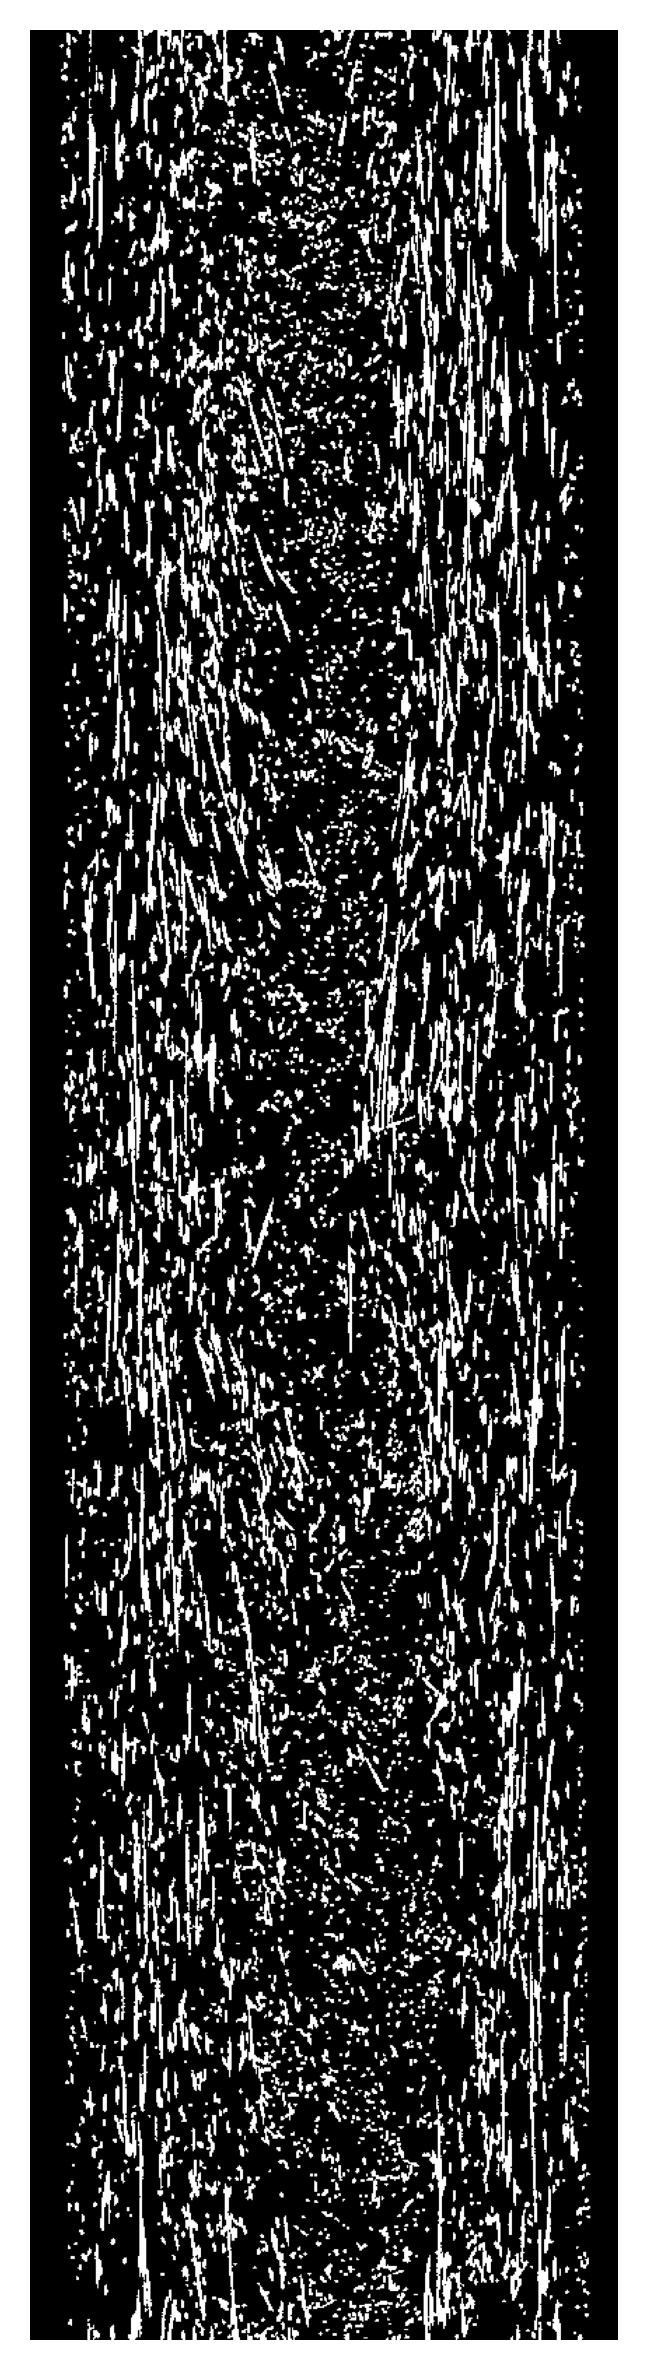

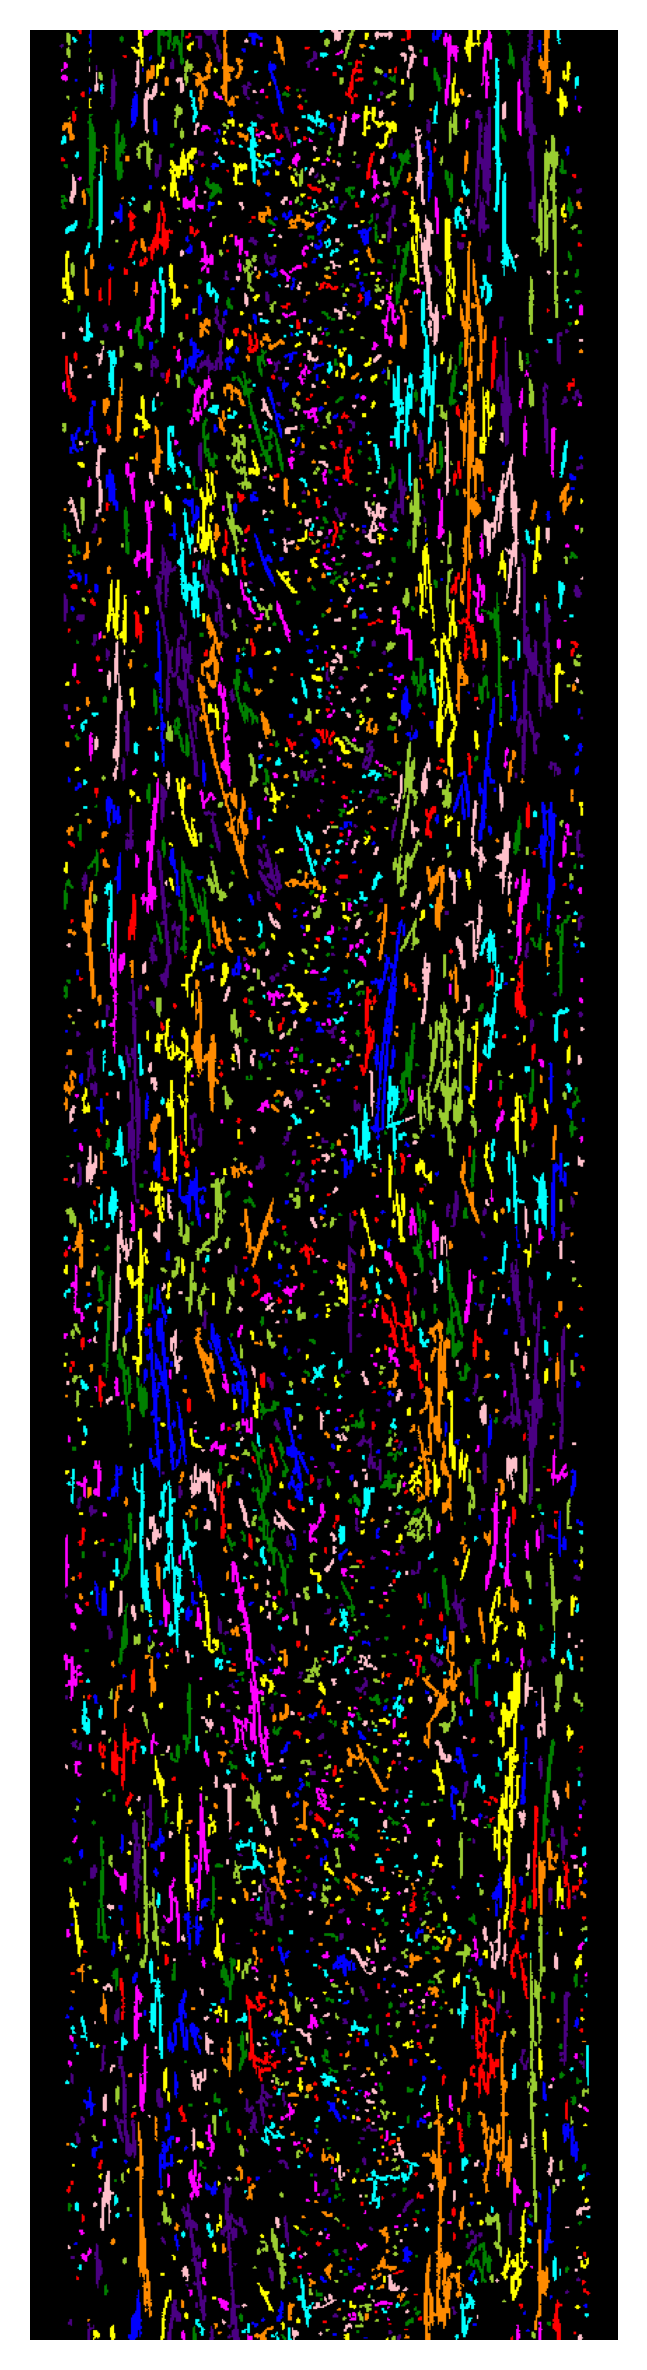

In [3]:
img = Image.open("./fiber_img/slice_400.tiff").convert("L")
imagem = np.array(img)
binaria = imagem > 200
binaria_limpa = remove_small_objects(binaria, min_size=50)

plt.figure(figsize=(10, 10), dpi=300)
plt.imshow(binaria_limpa, cmap='gray')
plt.axis('off')
plt.show()

rotulada = label(binaria_limpa, connectivity=2)

plt.figure(figsize=(10, 10), dpi=300)
plt.imshow(label2rgb(rotulada, bg_label=0), cmap='gray')
plt.axis('off')
plt.show()

Encontrados 5046 pontos de junção. Colorindo de vermelho e removendo...


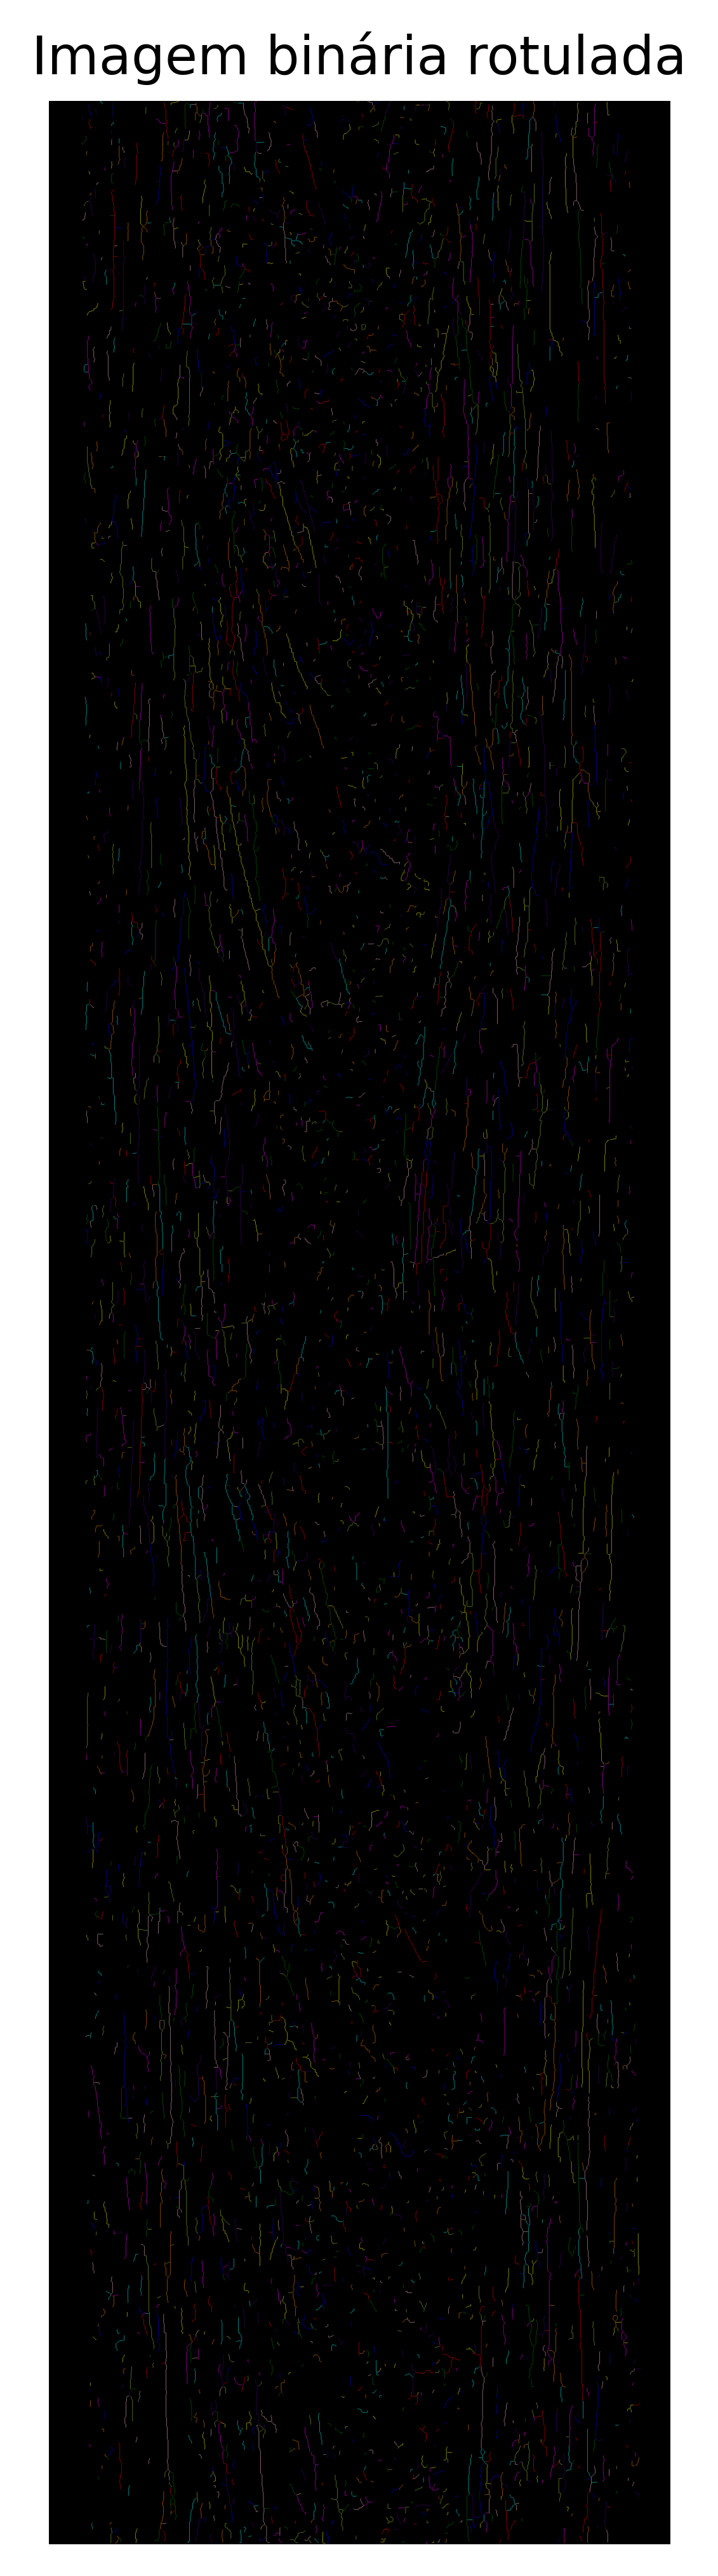

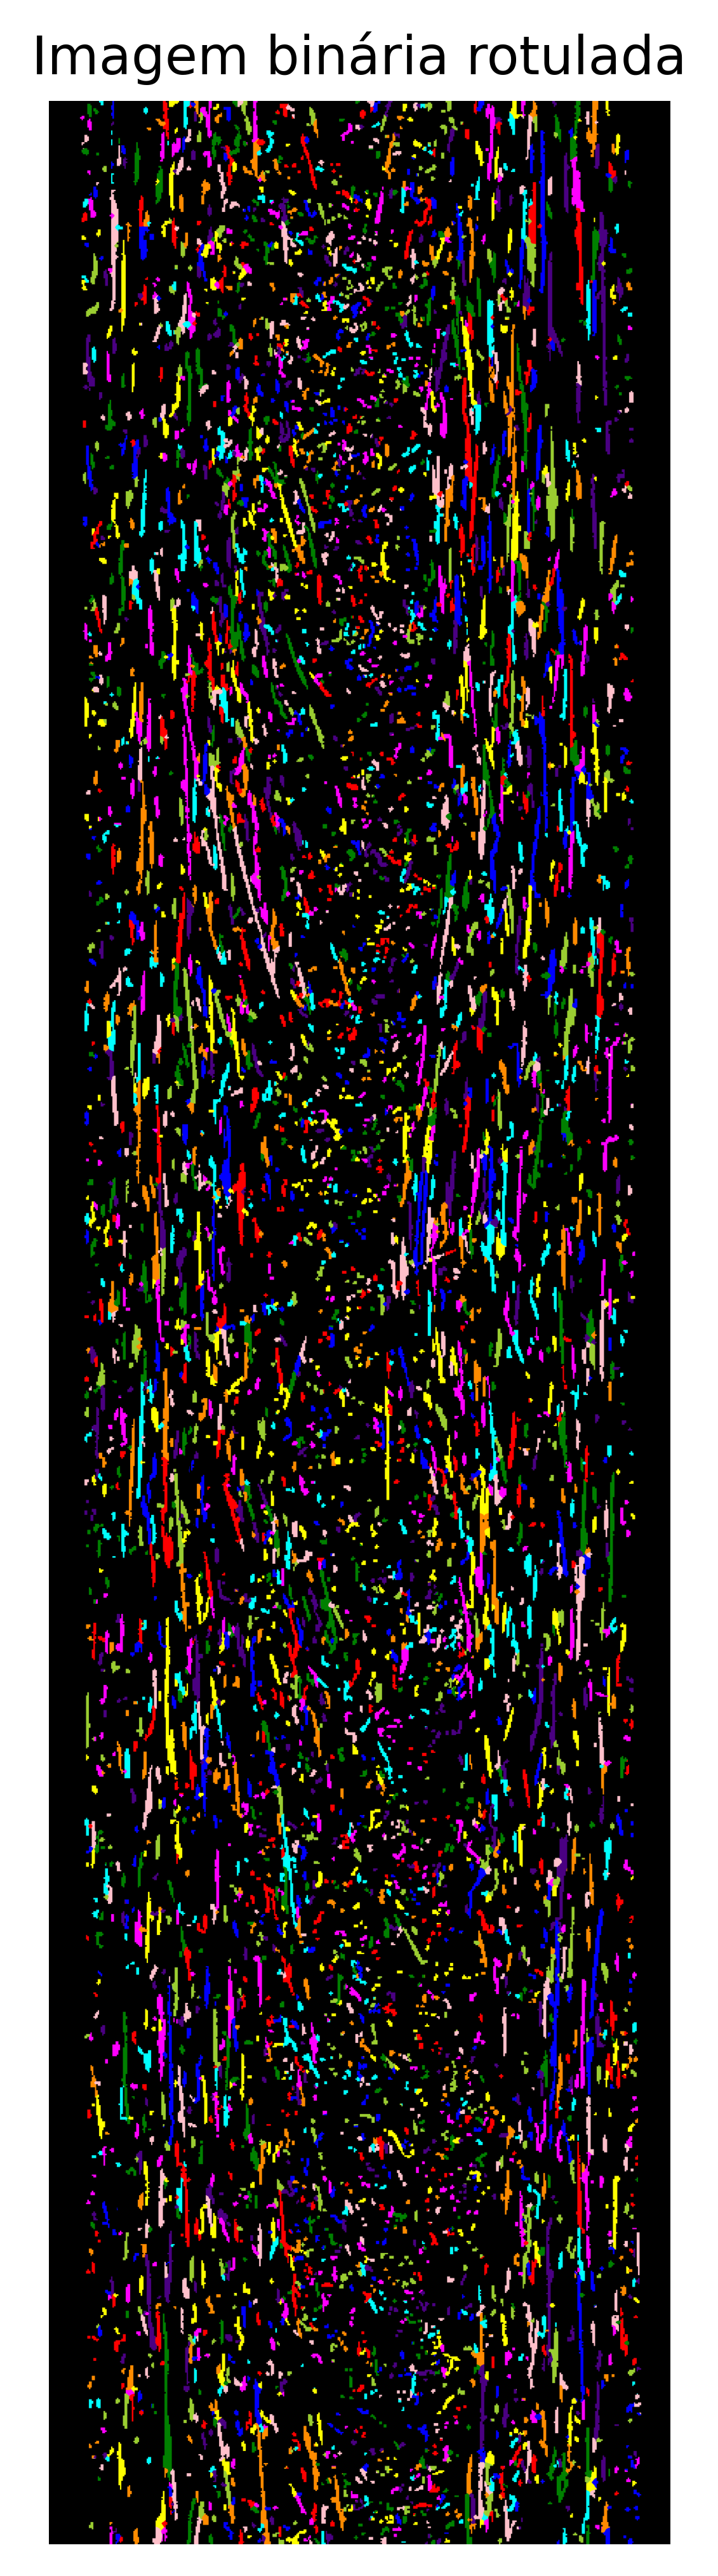

In [5]:
esqueleto_colorido, esqueleto_rotulado, esqueleto_sem_juncoes, binary_rotulada = label_binary_img(
    binaria_limpa, connectivity=2, remove_small_obj=True, min_size=10)

plt.figure(figsize=(10, 10), dpi=500)
plt.imshow(label2rgb(esqueleto_rotulado, bg_label=0), cmap='gray')
plt.title("Imagem binária rotulada")
plt.axis('off')
plt.show()

plt.figure(figsize=(10, 10), dpi=500)
plt.imshow(label2rgb(binary_rotulada, bg_label=0), cmap='gray')
plt.title("Imagem binária rotulada")
plt.axis('off')
plt.show()